In [1]:
import numbers
import warnings
from functools import partial
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.transforms import blended_transform_factory
from scipy.stats import permutation_test
from statsmodels.stats.multitest import multipletests

from mitox import setup_matplotlib

# Set my personal settings for matplotlib appearance.
setup_matplotlib(150)


In [2]:
df_all = pd.read_pickle("quantification/extracted_data.pickle")

# exclude = ["SKIN26", "SKIN16", "SKIN12"]

# for e in exclude:
#     df_all = df_all[df_all["MITOX ID"] != e]
# df_all = df_all.copy()

# Rescale quantities to make the plot ranges more readable (doesn't affect results.)
df_all["sO2_Median"] *= 100
df_all["sO2_Mean"] *= 100
df_all["THb_Median"] *= 1e6
df_all["THb_Mean"] *= 1e6

# Select only the median values where the negative pixels have been excluded.
spectrum_quantity = "Spectrum_Positive_Mean"

# These are the wavelengths we'll tend to analyse.
# There is some variability in the wavelengths used in acquisition, so we will just focus on these.
CHOSEN_WAVELENGTHS = np.array([
    700.0,
    730.0,
    760.0,
    800.0,
    850.0,
    910.0,
    930.0,
    950.0,
    980.0,
    1030.0,
    1080.0,
    1100.0,
])


In [3]:
# We will compute the ratios between spectrum positive medians.

# First, get all unique wavelengths in the dataset.
all_wavelengths = df_all["Spectrum_Wavelengths"].apply(set)
all_wavelengths = sorted(map(float, set.union(*all_wavelengths)))

ratio_columns = []

for wl1 in all_wavelengths:
    for wl2 in all_wavelengths:
        if wl1 != wl2:
            with warnings.catch_warnings(action="ignore"):
                # Catch the fragmentation warning.
                df_all[f"Ratio{wl1:.0f}-{wl2:.0f}"] = np.nan
                ratio_columns.append(f"Ratio{wl1:.0f}-{wl2:.0f}")

# Defragment the dataframe for speed of later computations.
df_all = df_all.copy()

for r, row in df_all.iterrows():
    for i, wl1 in enumerate(row["Spectrum_Wavelengths"]):
        for j, wl2 in enumerate(row["Spectrum_Wavelengths"]):
            if i == j:
                continue

            # Calculate the ratio of
            df_all.loc[r, f"Ratio{wl1:.0f}-{wl2:.0f}"] = (
                row[spectrum_quantity][i] / row[spectrum_quantity][j]
            )

aggregator_function = {
    a: "median"  # Median for numerics
    if isinstance(df_all[a].iloc[0], numbers.Number)
    else "first"  # Median for non-numeric scalars.
    if np.isscalar(df_all[a].iloc[0])
    else lambda x: np.nanmedian(np.stack(x), axis=0)  # Nanmedian for numeric arrays.
    for a in df_all.columns
}


In [4]:
def _compare_statistic(x, y, axis=None):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)


def compare_independent(df, column, groupby, pairwise=False) -> dict:
    # Ensure that values are not nans and are finite.
    df = df[~pd.isna(df[column])]
    df = df[np.isfinite(df[column])]

    # Collect the data into a list to be passed to the comparison function.
    grps = df.groupby(groupby)[column]
    to_test = [g.values for _, g in grps]
    labels = [n for n, _ in grps]
    if not pairwise and len(to_test) != 2:
        raise ValueError(
            "Only two groups can be compared unless pairwise is set to True"
        )
    if pairwise:
        # Do pairwise tests
        output = {}
        for i, j in combinations(range(len(to_test)), 2):
            output[f"{labels[i]}/{labels[j]}"] = permutation_test(
                (to_test[i], to_test[j]),
                _compare_statistic,
                vectorized=True,
                n_resamples=100000,
            )
        return output
    else:
        return {
            "test_result": permutation_test(
                to_test, _compare_statistic, vectorized=True, n_resamples=100000
            )
        }


In [5]:
df_skin_all = (
    df_all[df_all["ROI Name"] == "skin"].groupby("MITOX ID").agg(aggregator_function)
)


In [6]:
# Compare the imputed ITA values between the healthy volunteers and m.3243A>G.

ttest = compare_independent(df_skin_all, "ITA", "Group")["test_result"]

print(f"Before the ITA values are balanced, p = {ttest.pvalue:.4f}.")

print(
    "Minimum ITA value in m.3243A>G dataset is: {:.2f}".format(
        df_skin_all[df_skin_all["Group"] == "Affected patient"]["ITA"].min()
    )
)

# Filter the data to match the distributions of ITAs.
df = df_all[df_all["ITA"] > 23].copy()
del df_all  # To ensure we don't accidentally use this again.
df_skin = df[df["ROI Name"] == "skin"].groupby("MITOX ID").agg(aggregator_function)

ttest_skin_after = compare_independent(df_skin, "ITA", "Group")["test_result"]
print(f"After the ITA values are balanced, p = {ttest_skin_after.pvalue:.4f}.")


Before the ITA values are balanced, p = 0.0105.
Minimum ITA value in m.3243A>G dataset is: 23.89
After the ITA values are balanced, p = 0.8481.


In [7]:
display(df_skin_all.groupby("Group")["ITA"].mean())
display(df_skin_all.groupby("Group")["ITA"].std())


Group
Affected patient     48.030191
Healthy volunteer    20.945653
Name: ITA, dtype: float64

Group
Affected patient     12.549596
Healthy volunteer    35.817881
Name: ITA, dtype: float64

In [8]:
display(df_skin.groupby("Group")["ITA"].mean())
display(df_skin.groupby("Group")["ITA"].std())


Group
Affected patient     48.030191
Healthy volunteer    48.852489
Name: ITA, dtype: float64

Group
Affected patient     12.549596
Healthy volunteer    11.789376
Name: ITA, dtype: float64

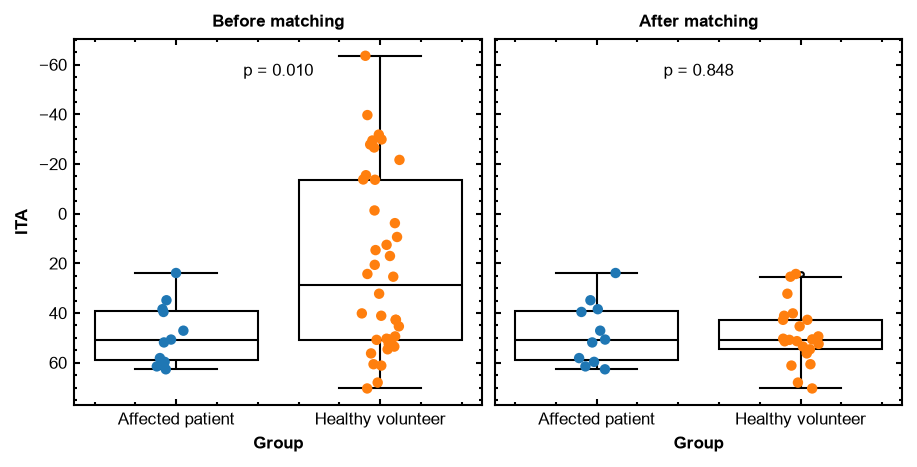

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True, sharex=True)

# Plot the distributions before they have been matched
sns.boxplot(df_skin_all, x="Group", y="ITA", ax=axes[0], color="w", linecolor="k")
sns.stripplot(df_skin_all, x="Group", y="ITA", hue="Group", ax=axes[0])
axes[0].text(
    0.5, 0.9, f"p = {ttest.pvalue:.3f}", ha="center", transform=axes[0].transAxes
)

# Plot the distributions after they have been matched.
sns.boxplot(df_skin, x="Group", y="ITA", ax=axes[1], color="w", linecolor="k")
sns.stripplot(df_skin, x="Group", y="ITA", hue="Group", ax=axes[1])
axes[1].text(
    0.5,
    0.9,
    f"p = {ttest_skin_after.pvalue:.3f}",
    ha="center",
    transform=axes[1].transAxes,
)

plt.gca().invert_yaxis()
axes[0].set_title("Before matching")
axes[1].set_title("After matching")
plt.show()


In [10]:
def get_row_wavelength(row, spectrum_quantity, wavelength):
    if wavelength in row["Spectrum_Wavelengths"]:
        # I appreciate this is really inefficient, but it is accurate...
        i = row["Spectrum_Wavelengths"].tolist().index(wavelength)
        return row[spectrum_quantity][i]
    else:
        return np.nan


In [11]:
# Check if any of the wavelengths in the skin differ significantly.
for i, wl in enumerate(CHOSEN_WAVELENGTHS):
    df_skin["S"] = df_skin.apply(
        partial(get_row_wavelength, spectrum_quantity=spectrum_quantity, wavelength=wl),
        axis=1,
    )

    print(
        wl,
        {
            "Skin: " + k: f"p = {t.pvalue:.3f}"
            for k, t in compare_independent(
                df_skin[df_skin["Device S/N"] == "2-22-01"],
                "S",
                "Group",
                pairwise=True,
            ).items()
        },
    )


/var/folders/j_/tr170khd4szcb58bp9qlz61r0000gp/T/ipykernel_20501/3140140261.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_skin["S"] = df_skin.apply(


700.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.951'}
730.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.964'}
760.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.919'}
800.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.972'}
850.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.951'}
910.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.184'}
930.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.150'}
950.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.643'}
980.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.122'}
1030.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.542'}
1080.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.399'}
1100.0 {'Skin: Affected patient/Healthy volunteer': 'p = 0.727'}


In [12]:
df_bicep = (
    df[(df["ROI Name"] == "muscle") & (df["ROI Position"] == "ellipse")]
    .groupby("MITOX ID")
    .agg(aggregator_function)
).copy()

df_bicep_new_device = df_bicep[df_bicep["Device S/N"] == "2-22-01"].copy()

df_bicep_hv = df_bicep[df_bicep["Group"] == "Healthy volunteer"]


/var/folders/j_/tr170khd4szcb58bp9qlz61r0000gp/T/ipykernel_20501/7340974.py:36: RuntimeWarning: All-NaN slice encountered
  else lambda x: np.nanmedian(np.stack(x), axis=0)  # Nanmedian for numeric arrays.


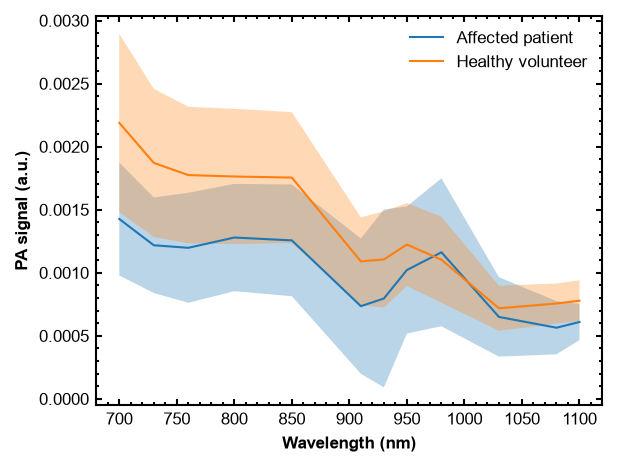

In [13]:
for i, (n, g) in enumerate(df_bicep_new_device.groupby("Group")):
    color = f"C{i}"

    specs = []
    for r, row in g.iterrows():
        wl_below1200 = row["Spectrum_Wavelengths"] < 1199
        wavelengths = row["Spectrum_Wavelengths"][wl_below1200]

        spec = np.interp(
            CHOSEN_WAVELENGTHS,
            wavelengths,
            row[spectrum_quantity][wl_below1200],
            np.nan,
            np.nan,
        )
        specs.append(spec)
    specs = np.stack(specs)

    m = np.nanmean(specs, axis=0)
    count = np.sum(~np.isnan(specs), axis=0)
    s = np.nanstd(specs, axis=0) / np.sqrt(count)
    plt.plot(CHOSEN_WAVELENGTHS, m, c=color, label=n)
    plt.fill_between(
        CHOSEN_WAVELENGTHS, m - 2 * s, m + 2 * s, facecolor=color, alpha=0.3
    )
plt.legend()
plt.xlabel("Wavelength (nm)")
plt.ylabel("PA signal (a.u.)")
plt.show()


In [14]:
# Check if any of the wavelengths in the skin differ significantly.
for i, wl in enumerate(CHOSEN_WAVELENGTHS):
    df_bicep_new_device["S"] = df_bicep_new_device.apply(
        partial(get_row_wavelength, spectrum_quantity=spectrum_quantity, wavelength=wl),
        axis=1,
    )

    print(
        wl,
        {
            k: f"{t.pvalue:.3f}"
            for k, t in compare_independent(
                df_bicep_new_device, "S", "Group", pairwise=True
            ).items()
        },
    )

# Calculate the statistics for the overall mean signal.
df_bicep_new_device["S"] = df_bicep_new_device[spectrum_quantity].apply(np.nanmean)
print(
    "Mean",
    dict([
        (k, f"{t.pvalue:.3f}")
        for k, t in compare_independent(
            df_bicep_new_device, "S", "Group", pairwise=True
        ).items()
    ]),
)

# Statistics for sO2 median, notably including all devices this time.
df_bicep["S"] = df_bicep["sO2_Median"]
print(
    "sO2",
    {
        k: f"{t.pvalue:.3f}"
        for k, t in compare_independent(
            df_bicep[df_bicep["sO2_Median"] > 20],  # Exclude the outlier
            "sO2_Median",
            "Group",
            pairwise=True,
        ).items()
    },
)

# THb median
df_bicep_new_device["S"] = df_bicep_new_device["THb_Median"]
print(
    "THb",
    {
        k: f"{t.pvalue:.3f}"
        for k, t in compare_independent(
            df_bicep_new_device, "THb_Median", "Group", pairwise=True
        ).items()
    },
)


700.0 {'Affected patient/Healthy volunteer': '0.276'}
730.0 {'Affected patient/Healthy volunteer': '0.255'}
760.0 {'Affected patient/Healthy volunteer': '0.281'}
800.0 {'Affected patient/Healthy volunteer': '0.373'}
850.0 {'Affected patient/Healthy volunteer': '0.339'}
910.0 {'Affected patient/Healthy volunteer': '0.341'}
930.0 {'Affected patient/Healthy volunteer': '0.495'}
950.0 {'Affected patient/Healthy volunteer': '0.570'}
980.0 {'Affected patient/Healthy volunteer': '0.836'}
1030.0 {'Affected patient/Healthy volunteer': '0.754'}
1080.0 {'Affected patient/Healthy volunteer': '0.234'}
1100.0 {'Affected patient/Healthy volunteer': '0.292'}
Mean {'Affected patient/Healthy volunteer': '0.322'}
sO2 {'Affected patient/Healthy volunteer': '0.240'}
THb {'Affected patient/Healthy volunteer': '0.412'}


In [15]:
# Check if any of the wavelengths in the skin differ significantly.
for i, wl in enumerate(CHOSEN_WAVELENGTHS):
    df_bicep_new_device["S"] = df_bicep_new_device.apply(
        partial(get_row_wavelength, spectrum_quantity=spectrum_quantity, wavelength=wl),
        axis=1,
    )

    print(
        wl,
        {
            k: f"{t.pvalue:.3f}"
            for k, t in compare_independent(
                df_bicep_new_device[
                    df_bicep_new_device["Group"] == "Healthy volunteer"
                ],
                "S",
                "Sex",
                pairwise=True,
            ).items()
        },
    )

# Calculate the statistics for the overall mean signal.
df_bicep_new_device["S"] = df_bicep_new_device[spectrum_quantity].apply(np.nanmean)
print(
    "Mean",
    {
        k: f"{t.pvalue:.3f}"
        for k, t in compare_independent(
            df_bicep_new_device[df_bicep_new_device["Group"] == "Healthy volunteer"],
            "S",
            "Sex",
            pairwise=True,
        ).items()
    },
)

# Statistics for sO2 median, notably including all devices this time.
df_bicep["S"] = df_bicep["sO2_Median"]
print(
    "sO2",
    {
        k: f"{t.pvalue:.3f}"
        for k, t in compare_independent(
            df_bicep[
                (df_bicep["Group"] == "Healthy volunteer")
                & (df_bicep["sO2_Median"] > 20)  # Exclude the outlier
            ],
            "sO2_Median",
            "Sex",
            pairwise=True,
        ).items()
    },
)

# THb median
df_bicep_new_device["S"] = df_bicep_new_device["THb_Median"]
print(
    "THb",
    {
        k: f"{t.pvalue:.3f}"
        for k, t in compare_independent(
            df_bicep_new_device[df_bicep_new_device["Group"] == "Healthy volunteer"],
            "THb_Median",
            "Sex",
            pairwise=True,
        ).items()
    },
)


700.0 {'Female/Male': '0.582'}
730.0 {'Female/Male': '0.700'}
760.0 {'Female/Male': '0.561'}
800.0 {'Female/Male': '0.800'}
850.0 {'Female/Male': '0.715'}
910.0 {'Female/Male': '0.380'}
930.0 {'Female/Male': '0.103'}
950.0 {'Female/Male': '0.438'}
980.0 {'Female/Male': '0.482'}
1030.0 {'Female/Male': '0.151'}
1080.0 {'Female/Male': '0.518'}
1100.0 {'Female/Male': '0.387'}
Mean {'Female/Male': '0.298'}
sO2 {'Female/Male': '0.137'}
THb {'Female/Male': '0.625'}


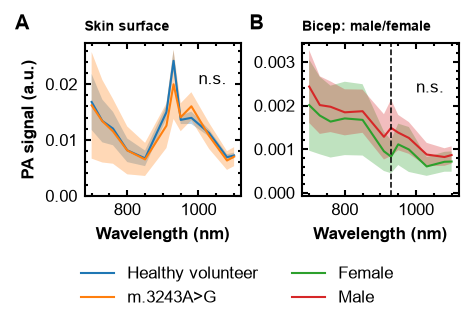

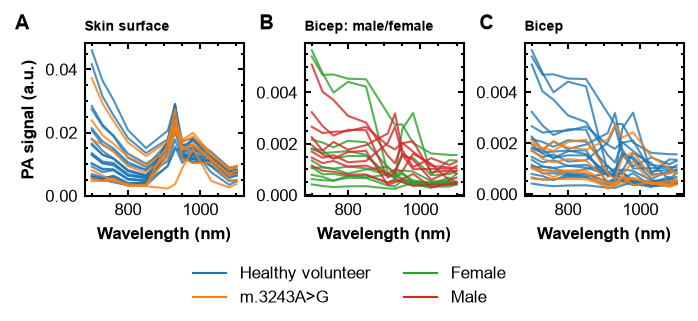

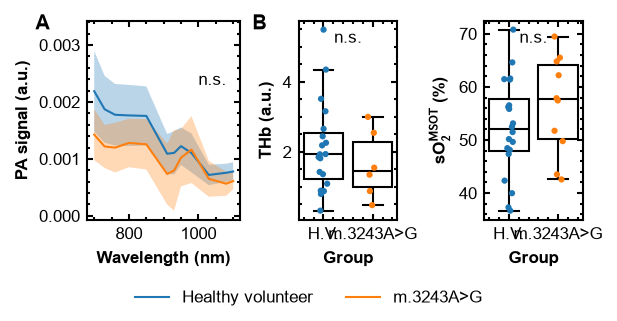

In [ ]:
fig1 = plt.figure(figsize=(3, 2))
fig3 = plt.figure(figsize=(4.5, 2))
fig2 = plt.figure(figsize=(4, 2))

subfigs = fig2.subfigures(1, 2, width_ratios=[1, 1.5])
assert isinstance(subfigs, np.ndarray)
axes_fig1 = fig1.subplots(1, 2, sharex=True)
axes_fig3 = fig3.subplots(1, 3, sharex=True)
axes_fig2 = subfigs[0].subplots()

axes_boxplots = subfigs[-1].subplots(1, 2, sharex=True)

axes = [axes_fig1[0], axes_fig1[1], axes_fig2]

fig1.text(0, 1, "A", va="top", ha="left", fontsize="large", fontweight="bold")
fig3.text(0, 1, "A", va="top", ha="left", fontsize="large", fontweight="bold")

subfigs[-1].text(0, 1, "B", va="top", ha="left", fontsize="large", fontweight="bold")

for ax in axes:
    ax.set_xlabel("Wavelength (nm)")
for ax in axes_fig3:
    ax.set_xlabel("Wavelength (nm)")
axes[0].set_ylabel("PA signal (a.u.)")
axes_fig3[0].set_ylabel("PA signal (a.u.)")
axes[-1].set_ylabel("PA signal (a.u.)")

for n in ["Healthy volunteer", "Affected patient"]:
    g = df_skin[df_skin["Device S/N"] == "2-22-01"]
    g = g[g["Group"] == n]
    specs = np.stack(g[spectrum_quantity])[:, :-1]
    m = np.nanmean(specs, axis=0)
    s = np.nanstd(specs, axis=0) / np.sqrt(specs.shape[0])
    line = axes[0].plot(
        CHOSEN_WAVELENGTHS, m, label=n if n == "Healthy volunteer" else "m.3243A>G"
    )
    axes[0].fill_between(CHOSEN_WAVELENGTHS, m - 2 * s, m + 2 * s, alpha=0.3)

    axes_fig3[0].plot(CHOSEN_WAVELENGTHS, specs.T, c=line[0].get_color(), alpha=0.8)

axes[0].text(1000, 0.02, "n.s.")
axes[0].set_title("Skin surface", loc="left", fontsize="small")
axes_fig3[0].set_title("Skin surface", loc="left", fontsize="small")
axes_fig3[2].set_title("Bicep", loc="left", fontsize="small")
axes[0].set_ylim([0, None])

i = 2
to_compare = []
for n, g in df_bicep_hv[df_bicep_hv["Device S/N"] == "2-22-01"].groupby("Sex"):
    specs = np.stack(g[spectrum_quantity])[:, :-1]
    to_compare.append(specs)
    m = np.nanmean(specs, axis=0)
    s = np.nanstd(specs, axis=0) / np.sqrt(specs.shape[0])
    line = axes[1].plot(CHOSEN_WAVELENGTHS, m, label=n, c=f"C{i}")
    axes[1].fill_between(
        CHOSEN_WAVELENGTHS, m - 2 * s, m + 2 * s, alpha=0.3, facecolor=f"C{i}"
    )

    axes_fig3[1].plot(CHOSEN_WAVELENGTHS, specs.T, c=line[0].get_color(), alpha=0.8)
    i += 1


axes[1].text(1000, 0.0023, "n.s.")
axes[1].set_title("Bicep: male/female", loc="left", fontsize="small")
axes_fig3[1].set_title("Bicep: male/female", loc="left", fontsize="small")

to_compare = []
for n in ["Healthy volunteer", "Affected patient"]:
    g = df_bicep_new_device
    g = g[g["Group"] == n]
    specs = np.stack(g[spectrum_quantity])[:, :-1]
    to_compare.append(specs)
    m = np.nanmean(specs, axis=0)
    s = np.nanstd(specs, axis=0) / np.sqrt(specs.shape[0])
    line = axes[2].plot(
        CHOSEN_WAVELENGTHS, m, label=n if n == "Healthy volunteer" else "m.3243A>G"
    )
    axes[2].fill_between(CHOSEN_WAVELENGTHS, m - 2 * s, m + 2 * s, alpha=0.3)

    axes_fig3[2].plot(CHOSEN_WAVELENGTHS, specs.T, c=line[0].get_color(), alpha=0.8)

axes[2].text(1000, 0.0023, "n.s.")
# axes[2].set_title("Bicep", loc="left", fontsize="small")
axes[2].sharey(axes[1])

sns.stripplot(
    df_bicep_new_device,
    x="Group",
    y="THb_Median",
    hue="Group",
    ax=axes_boxplots[0],
    order=["Healthy volunteer", "Affected patient"],
    hue_order=["Healthy volunteer", "Affected patient"],
    size=3,
)
sns.boxplot(
    df_bicep_new_device,
    x="Group",
    y="THb_Median",
    # hue="Group",
    ax=axes_boxplots[0],
    order=["Healthy volunteer", "Affected patient"],
    # hue_order=["Healthy volunteer", "Affected patient"],
    color="w",
    linecolor="k",
    fliersize=0,
)
axes_boxplots[0].set_xticks([0, 1], ["H.V.", "m.3243A>G"])
axes_boxplots[1].set_xticks([0, 1], ["H.V.", "m.3243A>G"])

# Compare the bicep sO2 Median between the two groups.
sns.stripplot(
    df_bicep[
        df_bicep["sO2_Median"] > 20
    ],  # Exclude the outlier  # [df_bicep["Device S/N"] == "2-22-01"],
    x="Group",
    y="sO2_Median",
    hue="Group",
    ax=axes_boxplots[1],
    order=["Healthy volunteer", "Affected patient"],
    hue_order=["Healthy volunteer", "Affected patient"],
    size=3,
)
sns.boxplot(
    df_bicep[
        df_bicep["sO2_Median"] > 20
    ],  # Exclude the outlier # [df_bicep["Device S/N"] == "2-22-01"], # Exclude the outlier
    x="Group",
    y="sO2_Median",
    # hue="Group",
    ax=axes_boxplots[1],
    order=["Healthy volunteer", "Affected patient"],
    # hue_order=["Healthy volunteer", "Affected patient"],
    color="w",
    linecolor="k",
    fliersize=0,
)
axes_boxplots[0].set_xticks([0, 1], ["H.V.", "m.3243A>G"])
axes_boxplots[1].set_xticks([0, 1], ["H.V.", "m.3243A>G"])
axes_boxplots[0].set_ylabel("THb (a.u.)")
axes_boxplots[1].set_ylabel(r"sO$_\mathbf{2}^\mathbf{MSOT}$ (%)")
axes_boxplots[0].set_xlabel("Group")
axes_boxplots[1].set_xlabel("Group")
axes[0].set_ylim([0, None])
axes_fig3[0].set_ylim([0, None])
leg = fig1.legend(loc="outside lower center", ncol=2)
fig3.legend(handles=leg.legend_handles, loc="outside lower center", ncol=2)

# t = axes[1].get_yticklabels()[1].get_transform()
fig1.text(
    -0.2,
    1,
    "B",
    fontsize="large",
    fontweight="bold",
    transform=blended_transform_factory(
        axes[1].get_yticklabels()[0].get_transform(), fig1.transFigure
    ),
    clip_on=False,
    in_layout=False,
    va="top",
    ha="right",
)
subfigs[0].text(
    -0.2,
    1,
    "A",
    fontsize="large",
    fontweight="bold",
    transform=blended_transform_factory(
        axes[2].get_yticklabels()[0].get_transform(), subfigs[0].transSubfigure
    ),
    clip_on=False,
    in_layout=False,
    va="top",
    ha="right",
)


fig3.text(
    -0.15,
    1,
    "B",
    fontsize="large",
    fontweight="bold",
    transform=blended_transform_factory(
        axes_fig3[1].get_yticklabels()[0].get_transform(), fig3.transFigure
    ),
    clip_on=False,
    in_layout=False,
    va="top",
    ha="right",
)

fig3.text(
    -0.15,
    1,
    "C",
    fontsize="large",
    fontweight="bold",
    transform=blended_transform_factory(
        axes_fig3[2].get_yticklabels()[0].get_transform(), fig3.transFigure
    ),
    clip_on=False,
    in_layout=False,
    va="top",
    ha="right",
)

axes_boxplots[0].text(
    0.5, 0.95, "n.s.", transform=axes_boxplots[0].transAxes, ha="center", va="top"
)
axes_boxplots[1].text(
    0.5, 0.95, "n.s.", transform=axes_boxplots[1].transAxes, ha="center", va="top"
)

axes[1].axvline(930, c="k", linestyle="--", linewidth=0.75)

fig2.legend(loc="outside lower center", ncols=2)

fig1.savefig("figures/compare_confounders.png", dpi=300)
fig2.savefig("figures/bicep_wavelength_unmixed.png", dpi=300)
fig3.savefig("figures/single_patient_plots.png", dpi=300)

plt.show()


In [17]:
selected_wavelengths = [800, 930, 980, 1030]


In [18]:
for r in ratio_columns:
    if all(x in selected_wavelengths for x in map(int, r[5:].split("-"))):
        try:
            test = compare_independent(df_bicep, r, "Group")["test_result"]
            if test.pvalue < 0.1:
                print(r, test.pvalue)
        except ValueError:
            # print(f"Can't evaluate {r}")
            continue


Ratio800-980 0.022239777602223978
Ratio800-1030 0.04049959500404996
Ratio930-980 0.047899521004789954
Ratio980-800 0.022259777402225976
Ratio1030-800 0.02079979200207998


In [19]:
def plot_ratio_box(r, ax: plt.Axes, df, group, show_p=False):
    if group == "Group":
        order = ["Healthy volunteer", "Affected patient"]
        xticks = ["H.V.", "m.3243A>G"]
        palette = None
    elif group == "Sex":
        order = ["Female", "Male"]
        xticks = order
        palette = ["C2", "C3"]
    elif group == "MuscleWeakness":
        order = ["Healthy volunteer", "No", "Yes"]
        xticks = order
        palette = ["C0", "C4", "C5"]

    sns.boxplot(
        df,
        x=group,
        y=r,
        ax=ax,
        color="w",
        linecolor="k",
        width=0.6,
        fliersize=False,
        order=order,
        legend=False,
    )
    sns.stripplot(
        df,
        x=group,
        y=r,
        ax=ax,
        size=3,
        hue=group,
        hue_order=order,
        order=order,
        legend=False,
        palette=palette,
    )

    ax.set_xticks(range(len(xticks)), xticks)
    ax.set_xticks([], [], minor=True)

    # ax.set_ylabel("Ratio")
    wl1, wl2 = r[5:].split("-")
    ax.set_ylabel(f"{wl1} nm / {wl2} nm")

    if show_p:
        test = compare_independent(df, r, group)["test_result"]
        print(f"p = {test.pvalue:.4f}, r = {r}, group = {group}")
        ax.text(
            0.5,
            0.95,
            f"p = {test.pvalue:.3f}" if test.pvalue < 0.06 else "n.s.",
            ha="center",
            va="top",
            transform=ax.transAxes,
        )


In [20]:
# Make a p-value heat map.

heatmap = np.ones((CHOSEN_WAVELENGTHS.size,) * 2)

for i, wl1 in enumerate(CHOSEN_WAVELENGTHS):
    for j, wl2 in enumerate(CHOSEN_WAVELENGTHS):
        if i == j:
            continue
        heatmap[i, j] = compare_independent(
            df_bicep, f"Ratio{wl1:.0f}-{wl2:.0f}", "Group"
        )["test_result"].pvalue


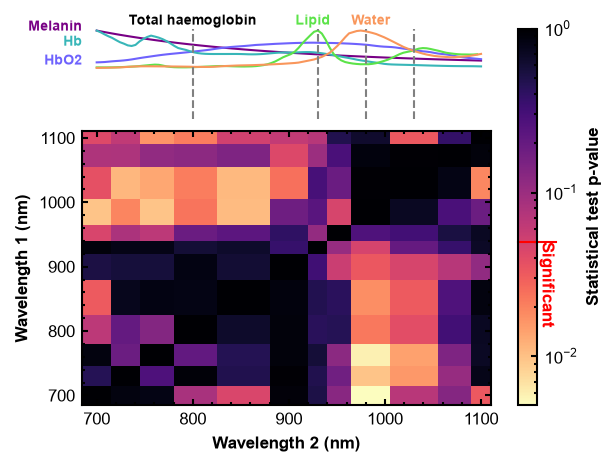

In [ ]:
from mitox import plot_all_spectra

fig, axes = plt.subplots(2, height_ratios=[0.75, 5], sharex=True)

im = axes[1].pcolormesh(
    CHOSEN_WAVELENGTHS, CHOSEN_WAVELENGTHS, heatmap, cmap="magma_r", norm="log"
)
cbar = plt.colorbar(im, ax=axes, label="Statistical test p-value")

cbar.ax.axhline(0.05, xmax=2, c="r", clip_on=False)
cbar.ax.text(
    1.1,
    0.05,
    "Significant",
    rotation=270,
    va="top",
    ha="left",
    color="red",
    transform=blended_transform_factory(cbar.ax.transAxes, cbar.ax.transData),
    fontweight="bold",
)

axes[1].set_ylabel("Wavelength 1 (nm)")
axes[1].set_xlabel("Wavelength 2 (nm)")


plot_all_spectra(axes[0], True, False)

axes[0].axis("off")
axes[0].axvline(800, ymin=-1.2, linestyle="--", c="gray", clip_on=False)
axes[0].axvline(930, ymin=-1.2, linestyle="--", c="gray", clip_on=False)
axes[0].axvline(980, ymin=-1.2, linestyle="--", c="gray", clip_on=False)
axes[0].axvline(1030, ymin=-1.2, linestyle="--", c="gray", clip_on=False)

axes[0].text(
    800,
    1.1,
    "Total haemoglobin",
    transform=blended_transform_factory(axes[0].transData, axes[0].transAxes),
    ha="center",
    fontsize="small",
    fontweight="bold",
)
axes[0].text(
    925,
    1.1,
    "Lipid",
    transform=blended_transform_factory(axes[0].transData, axes[0].transAxes),
    ha="center",
    fontsize="small",
    color=axes[0].get_lines()[3].get_color(),
    fontweight="bold",
)
axes[0].text(
    985,
    1.1,
    "Water",
    transform=blended_transform_factory(axes[0].transData, axes[0].transAxes),
    ha="center",
    fontsize="small",
    color=axes[0].get_lines()[4].get_color(),
    fontweight="bold",
)

axes[0].text(
    0,
    1,
    "Melanin",
    transform=blended_transform_factory(axes[0].transAxes, axes[0].transData),
    ha="right",
    fontsize="small",
    color=axes[0].get_lines()[0].get_color(),
    fontweight="bold",
)

axes[0].text(
    0,
    0.6,
    "Hb",
    transform=blended_transform_factory(axes[0].transAxes, axes[0].transData),
    ha="right",
    fontsize="small",
    color=axes[0].get_lines()[2].get_color(),
    fontweight="bold",
)

axes[0].text(
    0,
    0.1,
    "HbO2",
    transform=blended_transform_factory(axes[0].transAxes, axes[0].transData),
    ha="right",
    fontsize="small",
    color=axes[0].get_lines()[1].get_color(),
    fontweight="bold",
)
fig.savefig("figures/ratio_heatmap.png", dpi=300)
plt.show()


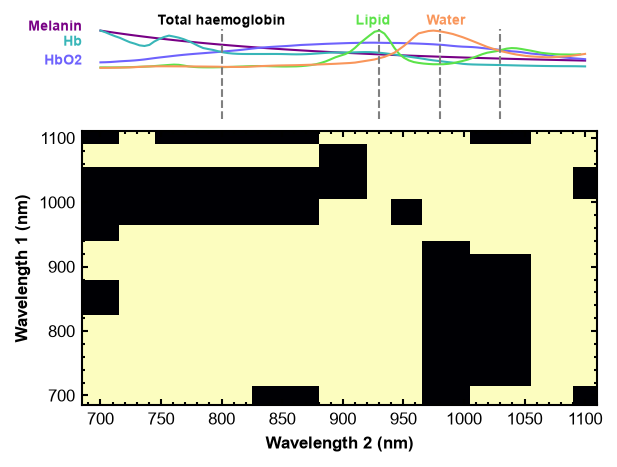

In [ ]:
fig, axes = plt.subplots(2, height_ratios=[0.75, 5], sharex=True)

im = axes[1].pcolormesh(
    CHOSEN_WAVELENGTHS, CHOSEN_WAVELENGTHS, heatmap < 0.05, cmap="magma_r", clim=(0, 1)
)

axes[1].set_ylabel("Wavelength 1 (nm)")
axes[1].set_xlabel("Wavelength 2 (nm)")


plot_all_spectra(axes[0], True, False)

axes[0].axis("off")
axes[0].axvline(800, ymin=-1.2, linestyle="--", c="gray", clip_on=False)
axes[0].axvline(930, ymin=-1.2, linestyle="--", c="gray", clip_on=False)
axes[0].axvline(980, ymin=-1.2, linestyle="--", c="gray", clip_on=False)
axes[0].axvline(1030, ymin=-1.2, linestyle="--", c="gray", clip_on=False)

axes[0].text(
    800,
    1.1,
    "Total haemoglobin",
    transform=blended_transform_factory(axes[0].transData, axes[0].transAxes),
    ha="center",
    fontsize="small",
    fontweight="bold",
)
axes[0].text(
    925,
    1.1,
    "Lipid",
    transform=blended_transform_factory(axes[0].transData, axes[0].transAxes),
    ha="center",
    fontsize="small",
    color=axes[0].get_lines()[3].get_color(),
    fontweight="bold",
)
axes[0].text(
    985,
    1.1,
    "Water",
    transform=blended_transform_factory(axes[0].transData, axes[0].transAxes),
    ha="center",
    fontsize="small",
    color=axes[0].get_lines()[4].get_color(),
    fontweight="bold",
)

axes[0].text(
    0,
    1,
    "Melanin",
    transform=blended_transform_factory(axes[0].transAxes, axes[0].transData),
    ha="right",
    fontsize="small",
    color=axes[0].get_lines()[0].get_color(),
    fontweight="bold",
)

axes[0].text(
    0,
    0.6,
    "Hb",
    transform=blended_transform_factory(axes[0].transAxes, axes[0].transData),
    ha="right",
    fontsize="small",
    color=axes[0].get_lines()[2].get_color(),
    fontweight="bold",
)

axes[0].text(
    0,
    0.1,
    "HbO2",
    transform=blended_transform_factory(axes[0].transAxes, axes[0].transData),
    ha="right",
    fontsize="small",
    color=axes[0].get_lines()[1].get_color(),
    fontweight="bold",
)
# fig.savefig("figures/ratio_heatmap.png", dpi=300)
plt.show()


In [23]:
heatmap[:, 0]


array([1.        , 0.44733553, 0.85547145, 0.06643934, 0.03201968,
       0.51929481, 0.88743113, 0.04569954, 0.0097399 , 0.03733963,
       0.07757922, 0.04197958])

In [24]:
df_details = pd.read_csv("../patient_details/MITOX_characteristics.csv", index_col=0)
for i in range(1, 43):
    i = str.zfill(str(i), 2)
    df_details.loc[f"SKIN{i}"] = pd.Series()
    df_details.loc[f"SKIN{i}", "MuscleWeakness"] = "Healthy volunteer"

df_detailed = df_bicep.merge(df_details, left_index=True, right_index=True)
df_detailed.loc[df_detailed["Group"] == "Healthy volunteer", "MuscleWeakness"] = (
    "Healthy volunteer"
)


p = 0.0236, r = Ratio980-800, group = Group
p = 0.0227, r = Ratio1030-800, group = Group
p = 0.5819, r = Ratio930-800, group = Group
p = 0.0473, r = Ratio930-980, group = Group


Healthy volunteer/No     0.204838
Healthy volunteer/Yes    0.004517
No/Yes                   0.183333
dtype: float64

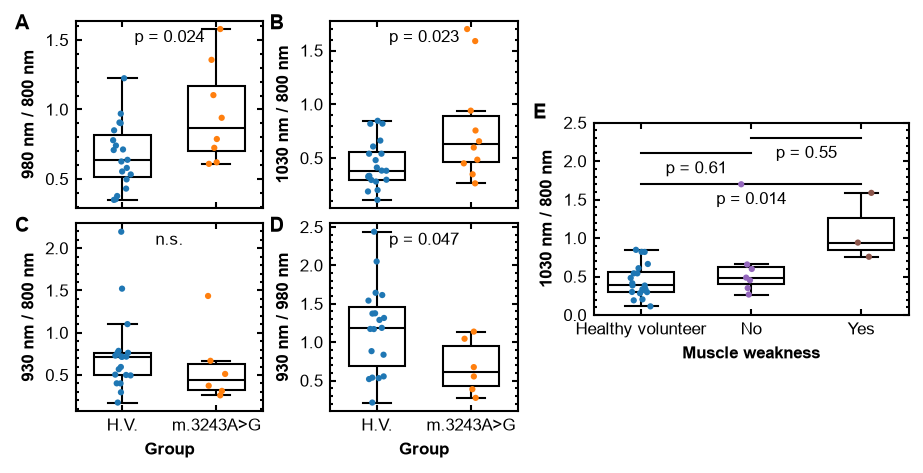

In [ ]:
fig = plt.figure(figsize=(6, 3))

subfiga, subfigb = fig.subfigures(1, 2, width_ratios=(1, 0.75))

axes = subfiga.subplots(2, 2, sharex=True)

plot_ratio_box("Ratio980-800", axes[0, 0], df_bicep, "Group", show_p=True)
plot_ratio_box("Ratio1030-800", axes[0, 1], df_bicep, "Group", show_p=True)
plot_ratio_box("Ratio930-800", axes[1, 0], df_bicep, "Group", show_p=True)
plot_ratio_box("Ratio930-980", axes[1, 1], df_bicep, "Group", show_p=True)

axes_b = subfigb.subplot_mosaic("""....\nBBBB\nBBBB\n....""")
ax = axes_b["B"]
plot_ratio_box("Ratio1030-800", ax, df_detailed, "MuscleWeakness", show_p=False)
ax.set_xlabel("Muscle weakness")

pvals_pairwise = pd.Series({
    k: v.pvalue
    for k, v in compare_independent(
        df_detailed, "Ratio1030-800", "MuscleWeakness", pairwise=True
    ).items()
})

display(pvals_pairwise)

# # Correct pairwise values by Bonferroni correction

_, corrected, _, _ = multipletests(pvals_pairwise, method="bonferroni")

pvals_pairwise[:] = corrected

# Add p-value annotations

ax.set_ylim([0, 2.5])
ax.plot([1, 2], [2.3, 2.3], c="k")
ax.text(1.5, 2.2, f"p = {pvals_pairwise['No/Yes']:.2f}", ha="center", va="top")
ax.plot([0, 1], [2.1, 2.1], c="k")
ax.text(
    0.5, 2.0, f"p = {pvals_pairwise['Healthy volunteer/No']:.2f}", ha="center", va="top"
)
ax.plot([0, 2], [1.7, 1.7], c="k")
ax.text(
    1, 1.6, f"p = {pvals_pairwise['Healthy volunteer/Yes']:.3f}", ha="center", va="top"
)

subfigb.text(
    0,
    1,
    "E",
    transform=blended_transform_factory(subfigb.transSubfigure, ax.transAxes),
    fontweight="bold",
    fontsize="large",
    va="bottom",
    ha="left",
)

subfiga.text(
    0,
    1,
    "A",
    transform=subfiga.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

subfiga.text(
    0,
    0.55,
    "C",
    transform=subfiga.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

subfiga.text(
    0.5,
    0.55,
    "D",
    transform=subfiga.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

subfiga.text(
    0.5,
    1,
    "B",
    transform=subfiga.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

subfiga.align_ylabels()

fig.savefig("figures/ratio_boxplots.png", dpi=300)
plt.show()


In [26]:
display(df_detailed.groupby("Group")[["Age_x", "ITA", "Het"]].mean())
display(df_detailed.groupby("Group")[["Age_x", "ITA", "Het"]].std())
# df_detailed.groupby("Group").count()


,Age_x,ITA,Het
Group,,,
Affected patient,42.636364,48.030191,24.888889
Healthy volunteer,46.000000,49.267084,NaN


,Age_x,ITA,Het
Group,,,
Affected patient,16.989837,12.549596,17.645427
Healthy volunteer,18.547237,11.915042,NaN


In [27]:
display(df_detailed.groupby("Group")[["Sex_x"]].value_counts())
display(df_detailed.groupby("Group")["MuscleWeakness"].value_counts())


Group              Sex_x 
Affected patient   Female     6
                   Male       5
Healthy volunteer  Female    13
                   Male       8
Name: count, dtype: int64

Group              MuscleWeakness   
Affected patient   No                    8
                   Yes                   3
Healthy volunteer  Healthy volunteer    21
Name: count, dtype: int64

In [28]:
df_detailed.sort_values("ITA")[["ITA", "Group", "Sex_x", "Het", "Age_x"]]


,ITA,Group,Sex_x,Het,Age_x
MITOX ID,,,,,
MITOX_19,23.885261,Affected patient,Male,39.0,29.0
SKIN26,24.270000,Healthy volunteer,Male,NaN,65.0
SKIN25,25.374000,Healthy volunteer,Male,NaN,22.0
SKIN15,32.224000,Healthy volunteer,Female,NaN,36.0
MITOX_11,34.853558,Affected patient,Female,13.0,43.0
MITOX_W3,38.455370,Affected patient,Male,58.0,20.0
MITOX_04,39.563665,Affected patient,Female,30.0,39.0
SKIN04,41.098000,Healthy volunteer,Female,NaN,25.0
SKIN07,42.734000,Healthy volunteer,Male,NaN,32.0


p = 0.9634, r = Ratio980-800, group = Sex
p = 0.2204, r = Ratio1030-800, group = Sex
p = 0.0586, r = Ratio930-800, group = Sex
p = 0.2356, r = Ratio930-980, group = Sex


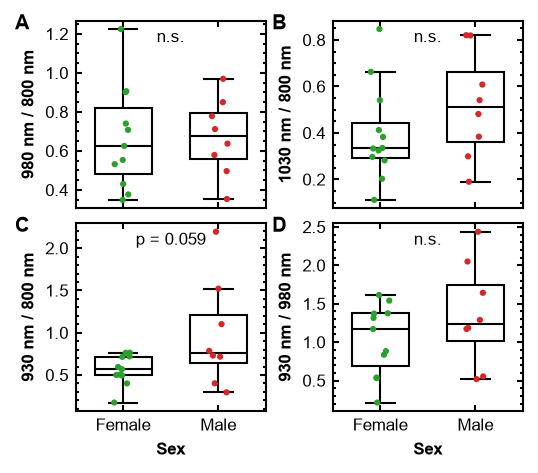

In [ ]:
fig = plt.figure(figsize=(6 / 1.75, 3))

axes = fig.subplots(2, 2, sharex=True)

plot_ratio_box(
    "Ratio980-800",
    axes[0, 0],
    df_bicep[df_bicep["Group"] == "Healthy volunteer"],
    "Sex",
    show_p=True,
)
plot_ratio_box(
    "Ratio1030-800",
    axes[0, 1],
    df_bicep[df_bicep["Group"] == "Healthy volunteer"],
    "Sex",
    show_p=True,
)
plot_ratio_box(
    "Ratio930-800",
    axes[1, 0],
    df_bicep[df_bicep["Group"] == "Healthy volunteer"],
    "Sex",
    show_p=True,
)
plot_ratio_box(
    "Ratio930-980",
    axes[1, 1],
    df_bicep[df_bicep["Group"] == "Healthy volunteer"],
    "Sex",
    show_p=True,
)

fig.text(
    0,
    1,
    "A",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.text(
    0,
    0.55,
    "C",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.text(
    0.5,
    0.55,
    "D",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.text(
    0.5,
    1,
    "B",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.align_ylabels()

fig.savefig("figures/ratio_boxplots_MF.png", dpi=300)
plt.show()


p = 0.7147, r = Ratio980-800, group = Group
p = 0.7448, r = Ratio1030-800, group = Group
p = 0.8868, r = Ratio930-800, group = Group
p = 0.0886, r = Ratio930-980, group = Group


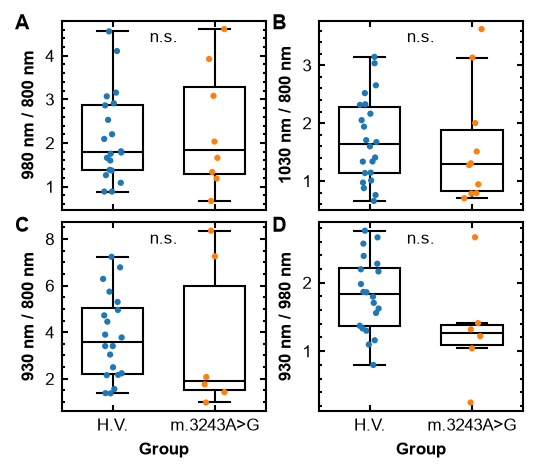

In [ ]:
fig = plt.figure(figsize=(6 / 1.75, 3))

axes = fig.subplots(2, 2, sharex=True)

plot_ratio_box(
    "Ratio980-800",
    axes[0, 0],
    df_skin,
    "Group",
    show_p=True,
)
plot_ratio_box(
    "Ratio1030-800",
    axes[0, 1],
    df_skin,
    "Group",
    show_p=True,
)
plot_ratio_box(
    "Ratio930-800",
    axes[1, 0],
    df_skin,
    "Group",
    show_p=True,
)
plot_ratio_box(
    "Ratio930-980",
    axes[1, 1],
    df_skin,
    "Group",
    show_p=True,
)

fig.text(
    0,
    1,
    "A",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.text(
    0,
    0.55,
    "C",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.text(
    0.5,
    0.55,
    "D",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.text(
    0.5,
    1,
    "B",
    transform=fig.transSubfigure,
    fontweight="bold",
    fontsize="large",
    va="top",
    ha="left",
)

fig.align_ylabels()

fig.savefig("figures/ratio_boxplots_skin.png", dpi=300)
plt.show()
